<center><h1>Yu_Stella_HW6</h1></center>

Name: Stella Yu
<br>
Github Username: syu35435-cmyk
<br>
USC ID: 3420585291

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

### (a) Download the APS Failure data

In [2]:
train_df = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na")
test_df = pd.read_csv("../data/aps_failure_test_set.csv", skiprows=20, na_values="na")

train_df.head()

,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Data imputation techniques for missing values include mean, median, and KNN. I picked mean imputation, which replaces missing values with the mean of each feature.

In [3]:
X_train = train_df.iloc[:, 1:].astype(float)
X_test = test_df.iloc[:, 1:].astype(float)
y_train = train_df.iloc[:, 0]
y_test = test_df.iloc[:, 0]

imputer = SimpleImputer(strategy="mean").set_output(transform="pandas")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

#### (ii) Calculate the coefficient of variation

In [4]:
cv = X_train.std() / X_train.mean()

print(cv)

aa_000      2.450938
ab_000      2.328400
ac_000      2.169767
ad_000    183.847620
ae_000     23.190937
             ...    
ee_007      4.962483
ee_008      3.222010
ee_009      5.626979
ef_000     47.124953
eg_000     40.553250
Length: 170, dtype: float64


#### (iii) Plot a correlation matrix

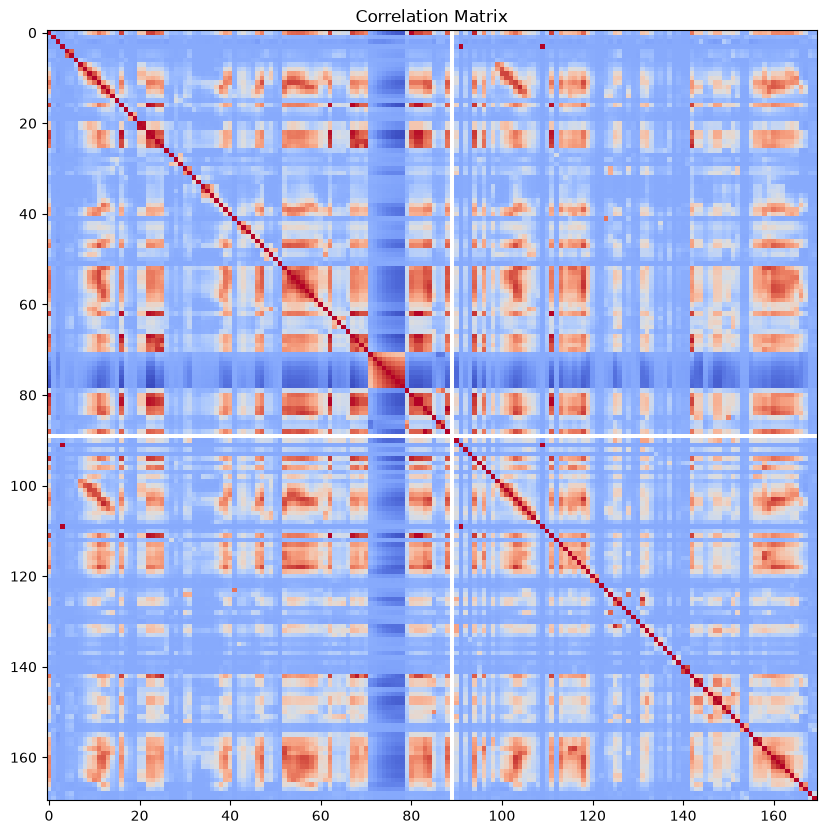

In [5]:
corr = X_train.corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

#### (iv) Make scatter plots and box plots

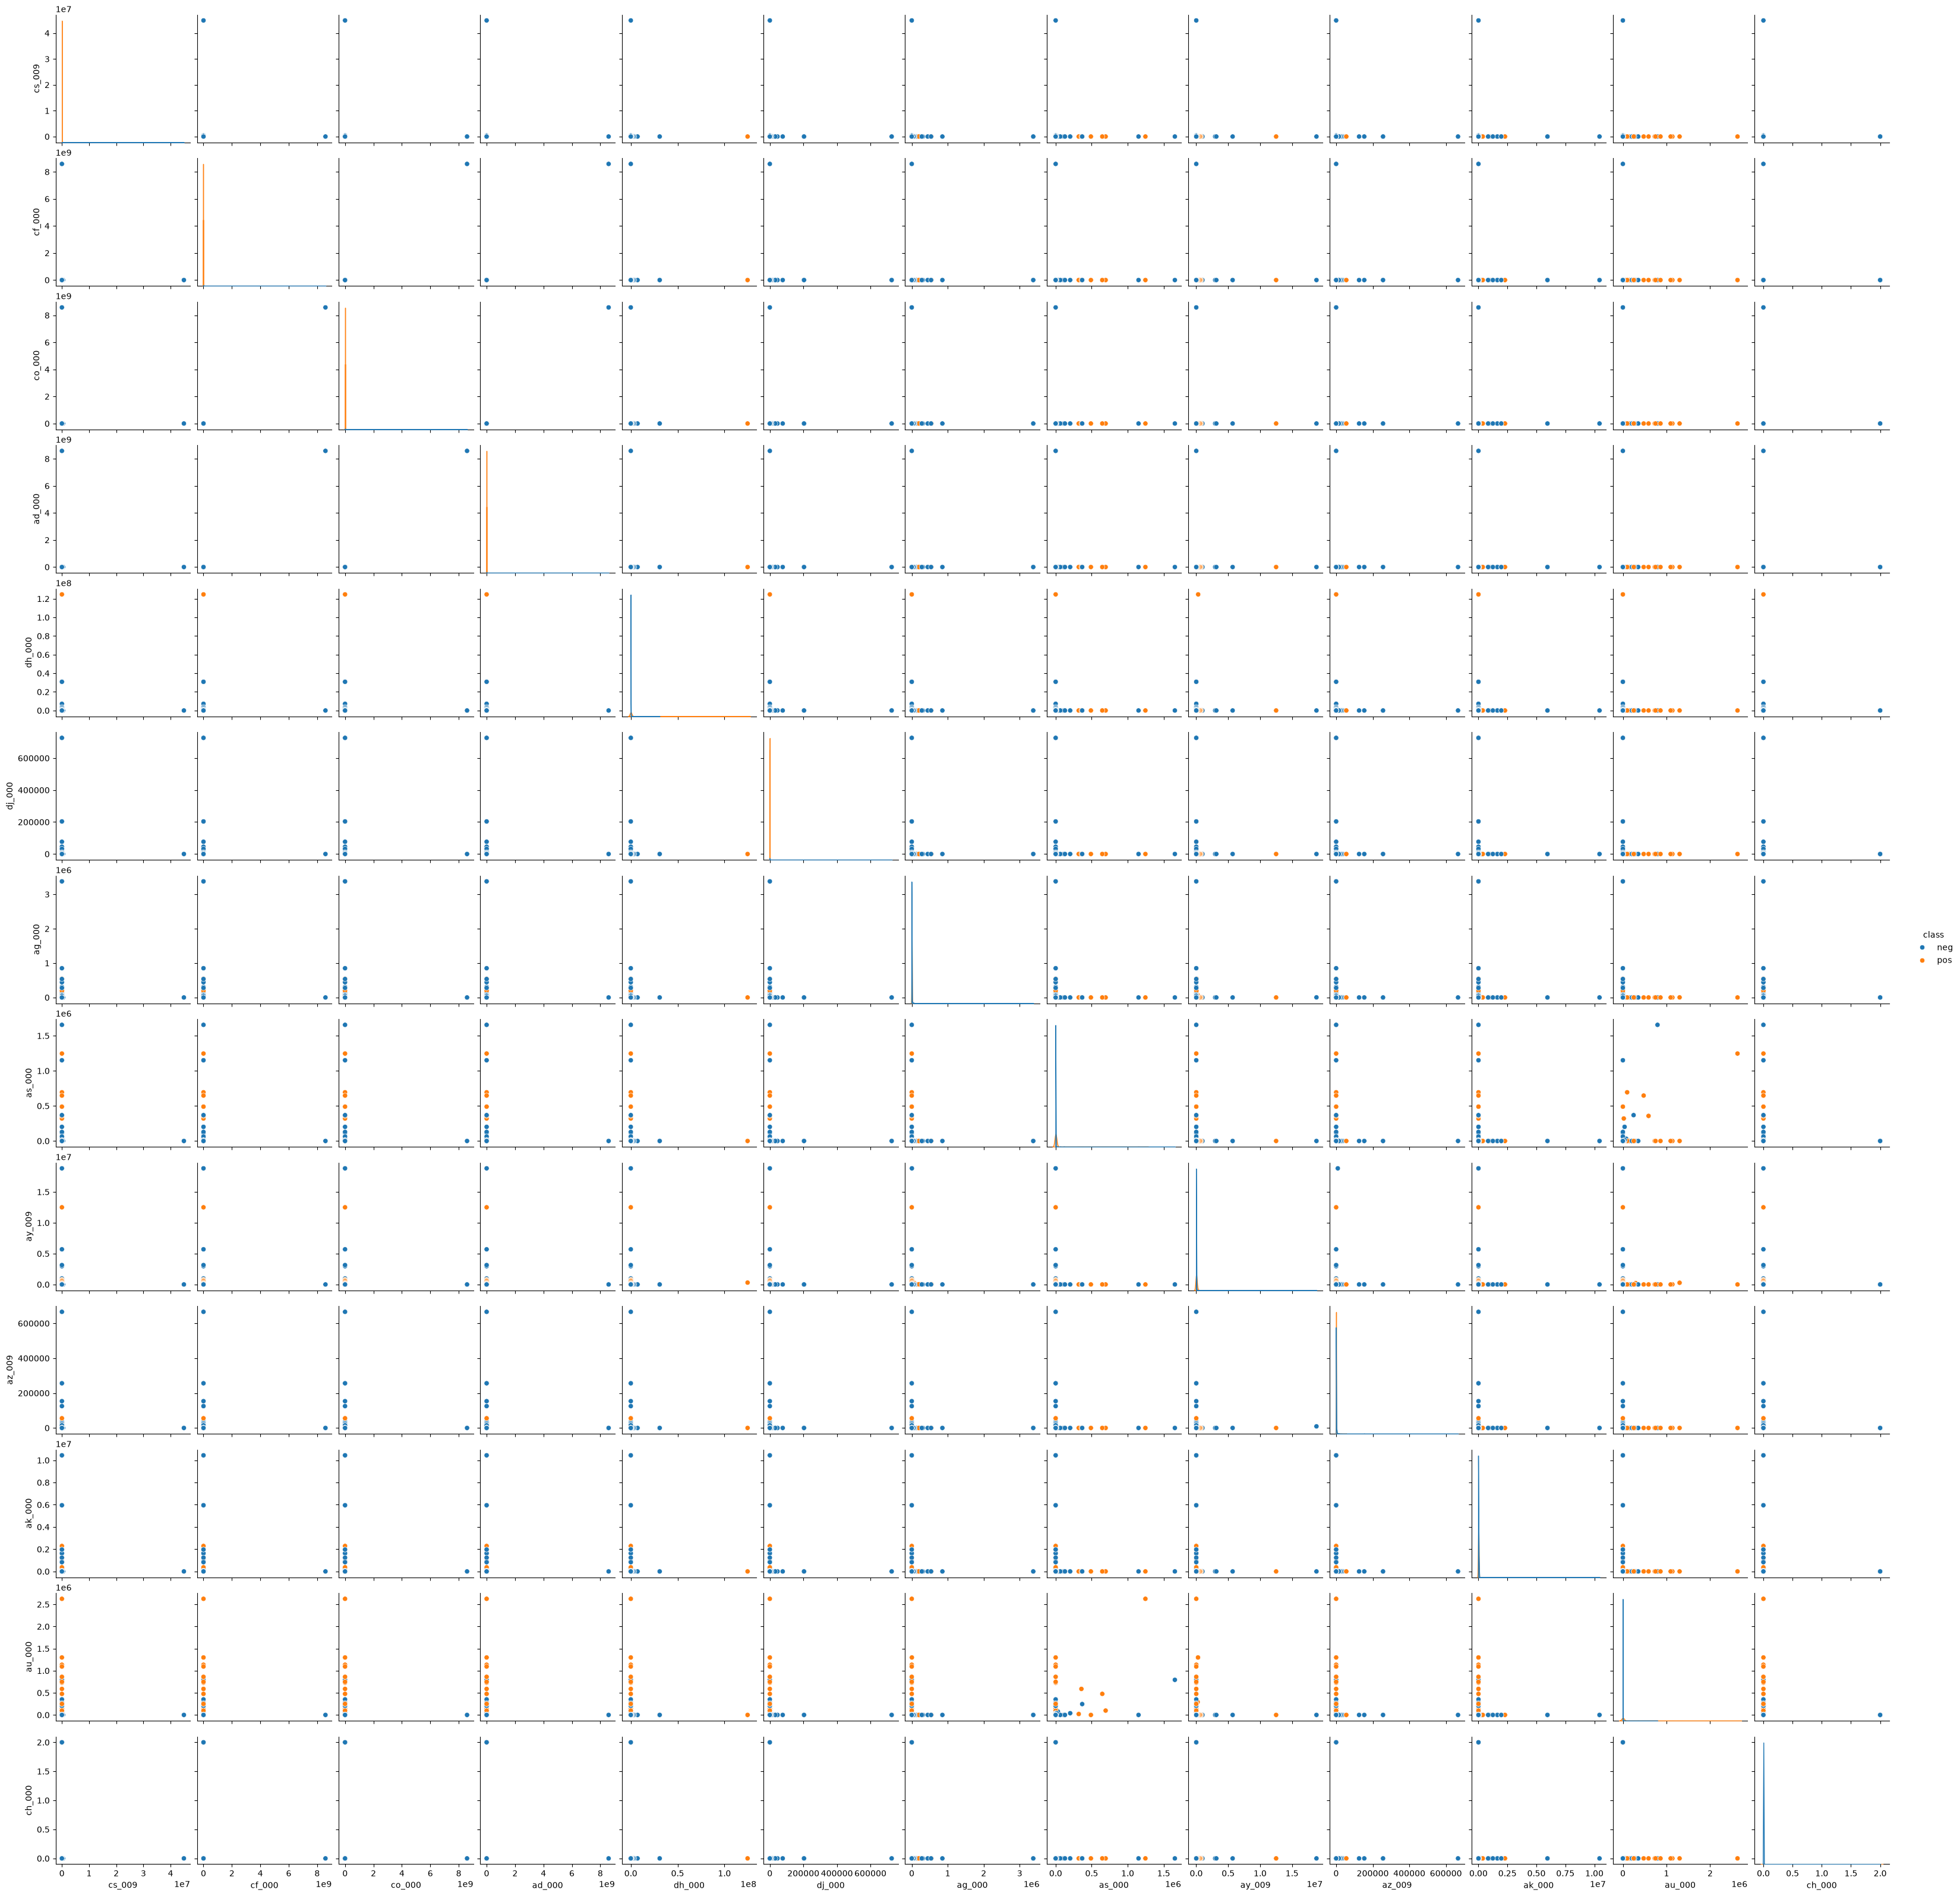

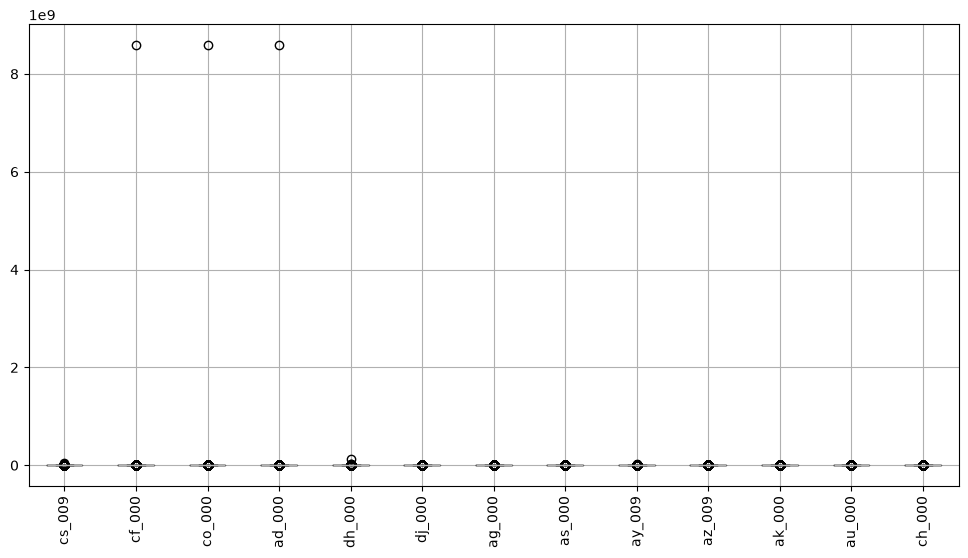

In [6]:
feature_cv = cv.nlargest(13)

plot_df = X_train[feature_cv.index].copy()
plot_df["class"] = y_train

sns.pairplot(plot_df, vars=feature_cv.index, hue="class")
plt.show()

X_train[feature_cv.index].boxplot(figsize=(12, 6))
plt.xticks(rotation=90)
plt.show()


Most of the points on the plot are near zero with some extreme outliers. The points overlap too much for the plots to draw conlusion about statistical significance. 

#### (v) Is this data set imbalanced?

In [7]:
print("Training set:")
print(y_train.value_counts())

print("\nTest set:")
print(y_test.value_counts())

Training set:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test set:
class
neg    15625
pos      375
Name: count, dtype: int64


The training set has 59000 negative values and 1000 positive values. Test set has 15625 negative and 375 positive. The dataset is very imbalanced because more than 90% of the data is negative.

### (c) Train a random forest

Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 1.666666666666483e-05
Training AUC: 0.9999999999999999

Test Confusion Matrix:
[[15609    16]
 [  107   268]]
Test Error: 0.007687499999999958
Test AUC: 0.9941591893333334
Out-of-bag Error: 0.006000000000000005


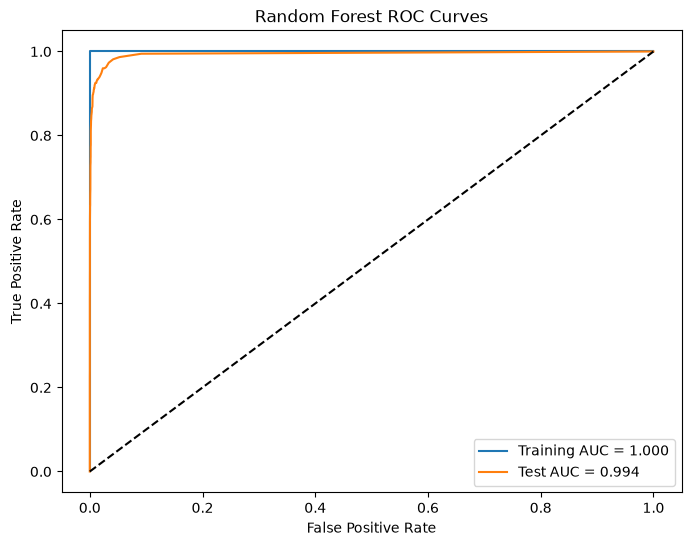

In [8]:
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_train)
cm = confusion_matrix(y_train, y_pred)

print("Training Confusion Matrix:")
print(cm)

train_accuracy = accuracy_score(y_train, y_pred)
train_error = 1 - train_accuracy

print("Training Error:", train_error)

y_prob = rf.predict_proba(X_train)[:, 1]

fpr, tpr, _ = roc_curve(y_train, y_prob, pos_label="pos")
train_auc = roc_auc_score(y_train, y_prob)

print("Training AUC:", train_auc)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Training AUC = %.3f" % train_auc)

y_test_pred = rf.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred)

print("\nTest Confusion Matrix:")
print(cm)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy

print("Test Error:", test_error)

y_prob = rf.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label="pos")
test_auc = roc_auc_score(y_test, y_prob)

print("Test AUC:", test_auc)
print("Out-of-bag Error:", 1 - rf.oob_score_)

plt.plot(fpr, tpr, label="Test AUC = %.3f" % test_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

The Out of bag error is 0.006 while test error is 0.007. These two values are close, with test error a bit higher than out of bag error. 

### (d) Research class imbalance in random forest

Class imbalanced can be addressed with class weights, oversampling, or undersampling. I used balanced class weights and compared to part c test error increased from 0.007 to 0.009, the AUC also decreased by 0.001. Part d performed worse. 

C:\Users\5809s\anaconda3\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Training Confusion Matrix:
[[58985    15]
 [    0  1000]]
Training Error: 0.00024999999999997247
Training AUC: 1.0

Test Confusion Matrix:
[[15573    52]
 [   94   281]]
Test Error: 0.00912500000000005
Test AUC: 0.993072384
Out-of-bag Error: 0.019950000000000023


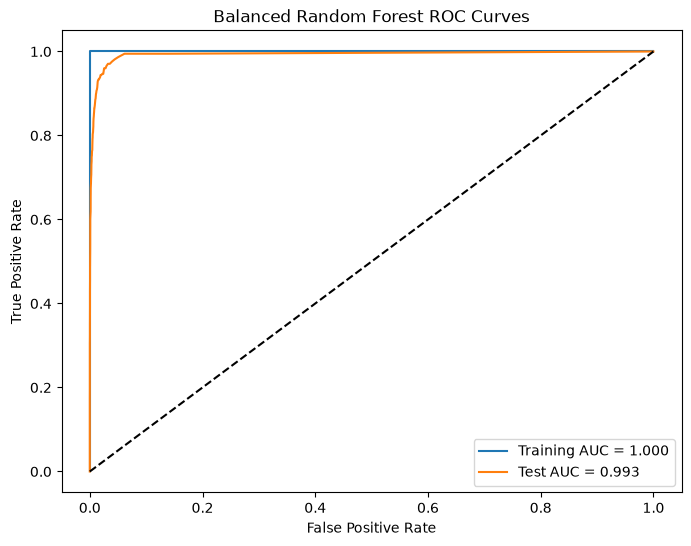

In [9]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_train)
cm = confusion_matrix(y_train, y_pred)

print("Training Confusion Matrix:")
print(cm)

train_accuracy = accuracy_score(y_train, y_pred)
train_error = 1 - train_accuracy

print("Training Error:", train_error)

y_prob = rf.predict_proba(X_train)[:, 1]

fpr, tpr, _ = roc_curve(y_train, y_prob, pos_label="pos")
train_auc = roc_auc_score(y_train, y_prob)

print("Training AUC:", train_auc)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Training AUC = %.3f" % train_auc)

y_test_pred = rf.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred)

print("\nTest Confusion Matrix:")
print(cm)

test_accuracy = accuracy_score(y_test, y_test_pred)
test_error = 1 - test_accuracy

print("Test Error:", test_error)

y_prob = rf.predict_proba(X_test)[:, 1]

fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label="pos")
test_auc = roc_auc_score(y_test, y_prob)

print("Test AUC:", test_auc)
print("Out-of-bag Error:", 1 - rf.oob_score_)

plt.plot(fpr, tpr, label="Test AUC = %.3f" % test_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC Curves")
plt.legend()
plt.show()

### (e) XGBoost and Model Trees

Best alpha: 0.1
Cross-validation Error: 0.0060833333333333295

Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 1.666666666666483e-05
Training AUC: 0.9999988644067798

Test Confusion Matrix:
[[15602    23]
 [   85   290]]
Test Error: 0.006750000000000034
Test AUC: 0.9929133226666667


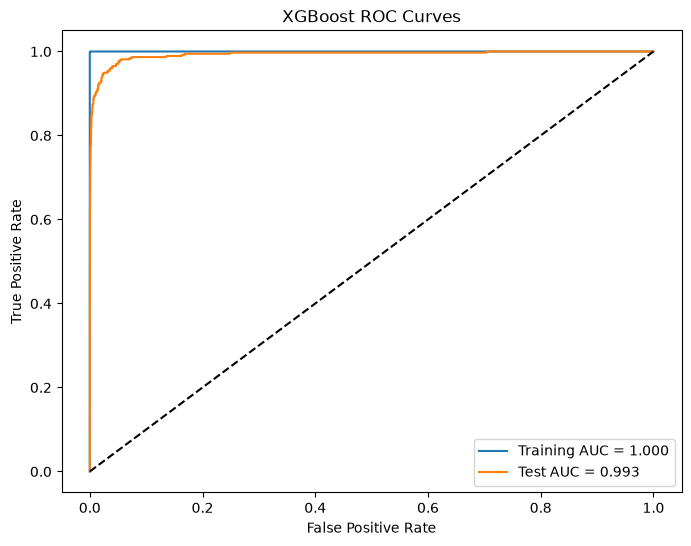

In [10]:
y_train_xgb = y_train.map({"neg": 0, "pos": 1})
y_test_xgb = y_test.map({"neg": 0, "pos": 1})

X_train_raw = train_df.drop(columns="class")
X_test_raw = test_df.drop(columns="class")

model = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("xgb", XGBClassifier(
        n_estimators=100,
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    model,
    param_grid={"xgb__reg_alpha": [0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=-1
)

grid.fit(X_train_raw, y_train_xgb)
xgb = grid.best_estimator_

print("Best alpha:", grid.best_params_["xgb__reg_alpha"])
print("Cross-validation Error:", 1 - grid.best_score_)

y_pred = xgb.predict(X_train_raw)
cm = confusion_matrix(y_train_xgb, y_pred)

print("\nTraining Confusion Matrix:")
print(cm)

train_accuracy = accuracy_score(y_train_xgb, y_pred)
train_error = 1 - train_accuracy

print("Training Error:", train_error)

y_prob = xgb.predict_proba(X_train_raw)[:, 1]

fpr, tpr, _ = roc_curve(y_train_xgb, y_prob)
train_auc = roc_auc_score(y_train_xgb, y_prob)

print("Training AUC:", train_auc)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Training AUC = %.3f" % train_auc)

y_test_pred = xgb.predict(X_test_raw)
cm = confusion_matrix(y_test_xgb, y_test_pred)

print("\nTest Confusion Matrix:")
print(cm)

test_accuracy = accuracy_score(y_test_xgb, y_test_pred)
test_error = 1 - test_accuracy

print("Test Error:", test_error)

y_prob = xgb.predict_proba(X_test_raw)[:, 1]

fpr, tpr, _ = roc_curve(y_test_xgb, y_prob)
test_auc = roc_auc_score(y_test_xgb, y_prob)

print("Test AUC:", test_auc)

plt.plot(fpr, tpr, label="Test AUC = %.3f" % test_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

### (f) Use SMOTE to pre-process your data

Best alpha: 0.1
Cross-validation Error: 0.0060833333333333295

Training Confusion Matrix:
[[59000     0]
 [    1   999]]
Training Error: 1.666666666666483e-05
Training AUC: 0.9999993389830508

Test Confusion Matrix:
[[15580    45]
 [   61   314]]
Test Error: 0.006624999999999992
Test AUC: 0.9938459306666666


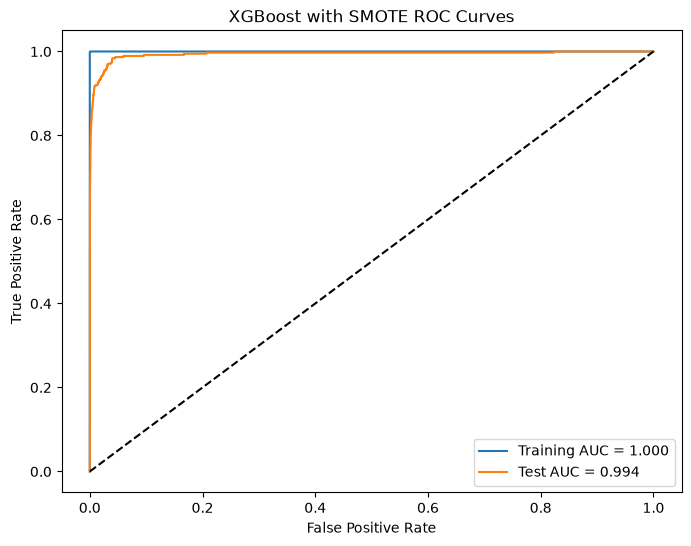

In [11]:
model = ImbPipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        n_estimators=100,
        objective="binary:logistic",
        tree_method="hist",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

grid = GridSearchCV(
    model,
    param_grid={"xgb__reg_alpha": [0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv_folds,
    n_jobs=1
)

grid.fit(X_train_raw, y_train_xgb)
xgb = grid.best_estimator_

print("Best alpha:", grid.best_params_["xgb__reg_alpha"])
print("Cross-validation Error:", 1 - grid.best_score_)

y_pred = xgb.predict(X_train_raw)
cm = confusion_matrix(y_train_xgb, y_pred)

print("\nTraining Confusion Matrix:")
print(cm)

train_accuracy = accuracy_score(y_train_xgb, y_pred)
train_error = 1 - train_accuracy

print("Training Error:", train_error)

y_prob = xgb.predict_proba(X_train_raw)[:, 1]

fpr, tpr, _ = roc_curve(y_train_xgb, y_prob)
train_auc = roc_auc_score(y_train_xgb, y_prob)

print("Training AUC:", train_auc)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label="Training AUC = %.3f" % train_auc)

y_test_pred = xgb.predict(X_test_raw)
cm = confusion_matrix(y_test_xgb, y_test_pred)

print("\nTest Confusion Matrix:")
print(cm)

test_accuracy = accuracy_score(y_test_xgb, y_test_pred)
test_error = 1 - test_accuracy

print("Test Error:", test_error)

y_prob = xgb.predict_proba(X_test_raw)[:, 1]

fpr, tpr, _ = roc_curve(y_test_xgb, y_prob)
test_auc = roc_auc_score(y_test_xgb, y_prob)

print("Test AUC:", test_auc)

plt.plot(fpr, tpr, label="Test AUC = %.3f" % test_auc)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost with SMOTE ROC Curves")
plt.legend()
plt.show()

Compared to part e, test error went from 0.00675 to 0.006625. AUC increased from 0.9929 to 0.9938. SMOTE achieved better results. 

## 2. ISLR 6.6.3

a) (iv) Steadily decreases. As s increase, the model will fit to the data more closely which makes RSS steadility decrease.

b) (ii) Decreases initially, then increases in a U shape. As s increases, the model will fit better at first, but it might overfit when s is too big, which increases test RSS.

c) (iii) Steadily increases. As s increases, the model becomes more flexible to the training data, which makes  variance increase.

d) (iv) Steadily decreases. As s increases, the model will fit to the data more closely which decreases squared bias.

e) (v) Remains constant. Irreducible error is related to noise in the data, s increasing does not effect it.

## 3. ISLR 6.6.5

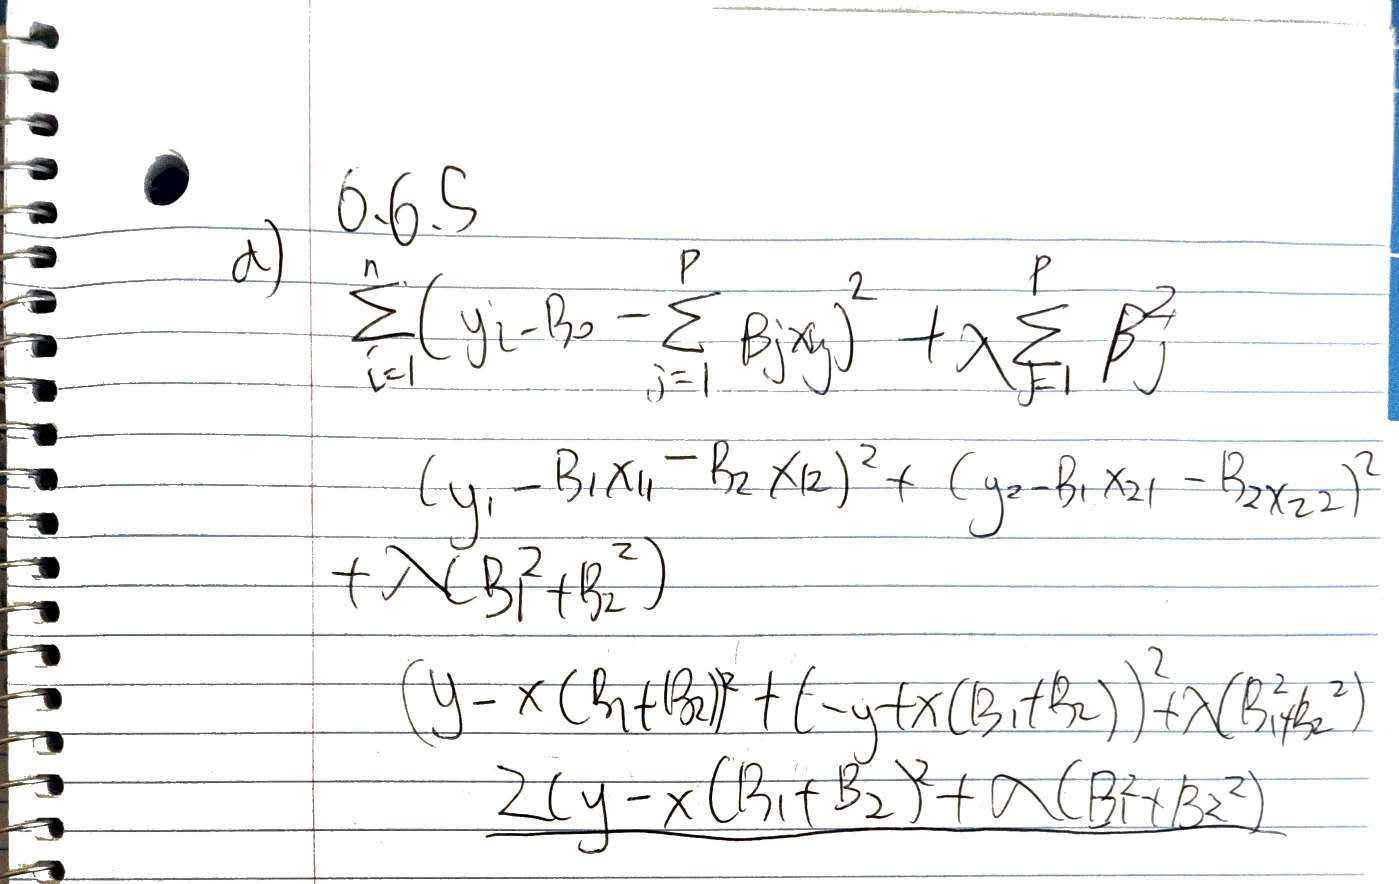

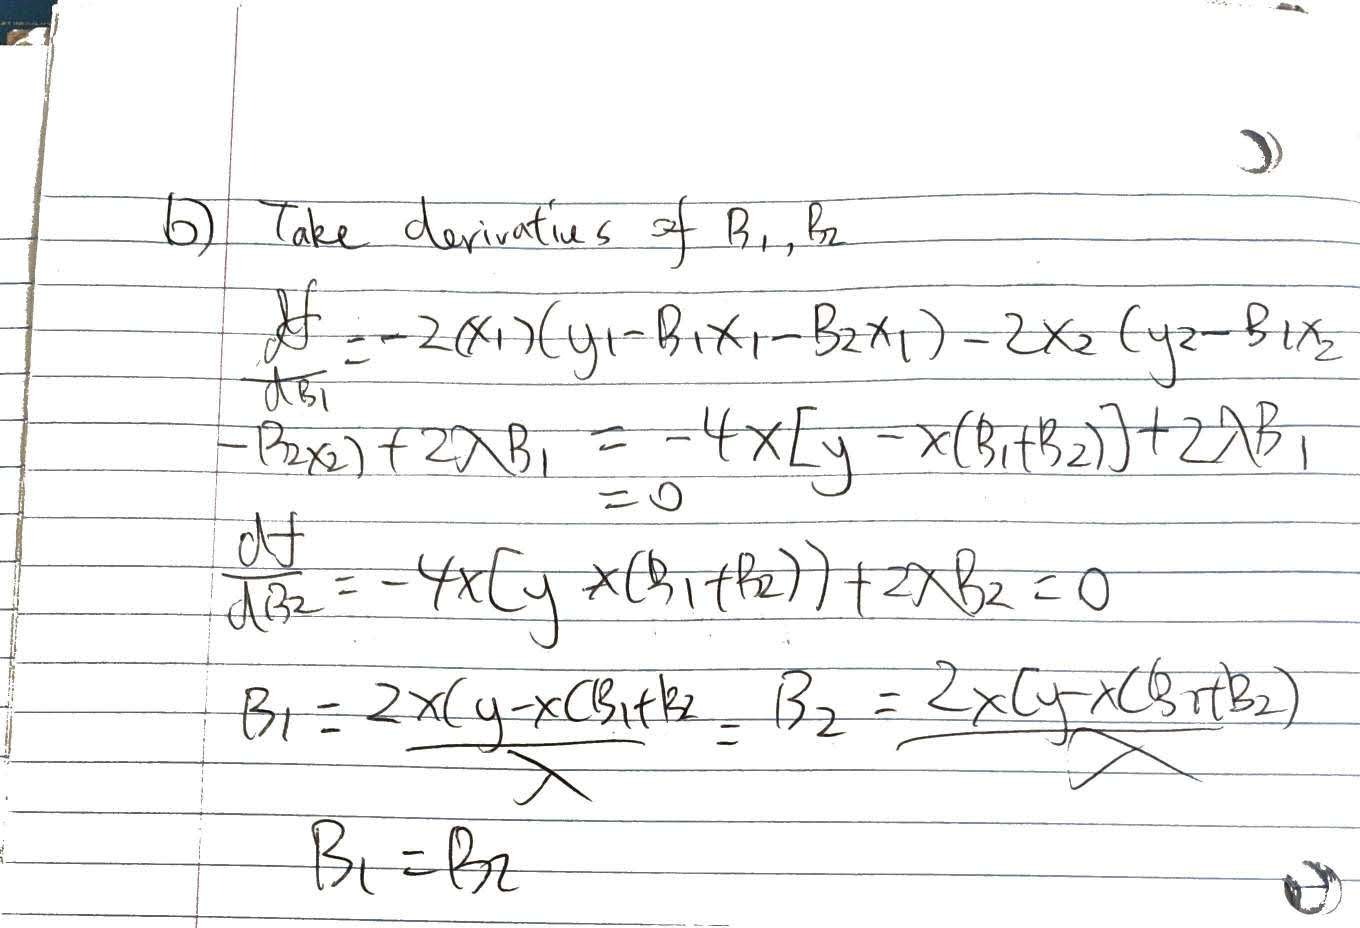

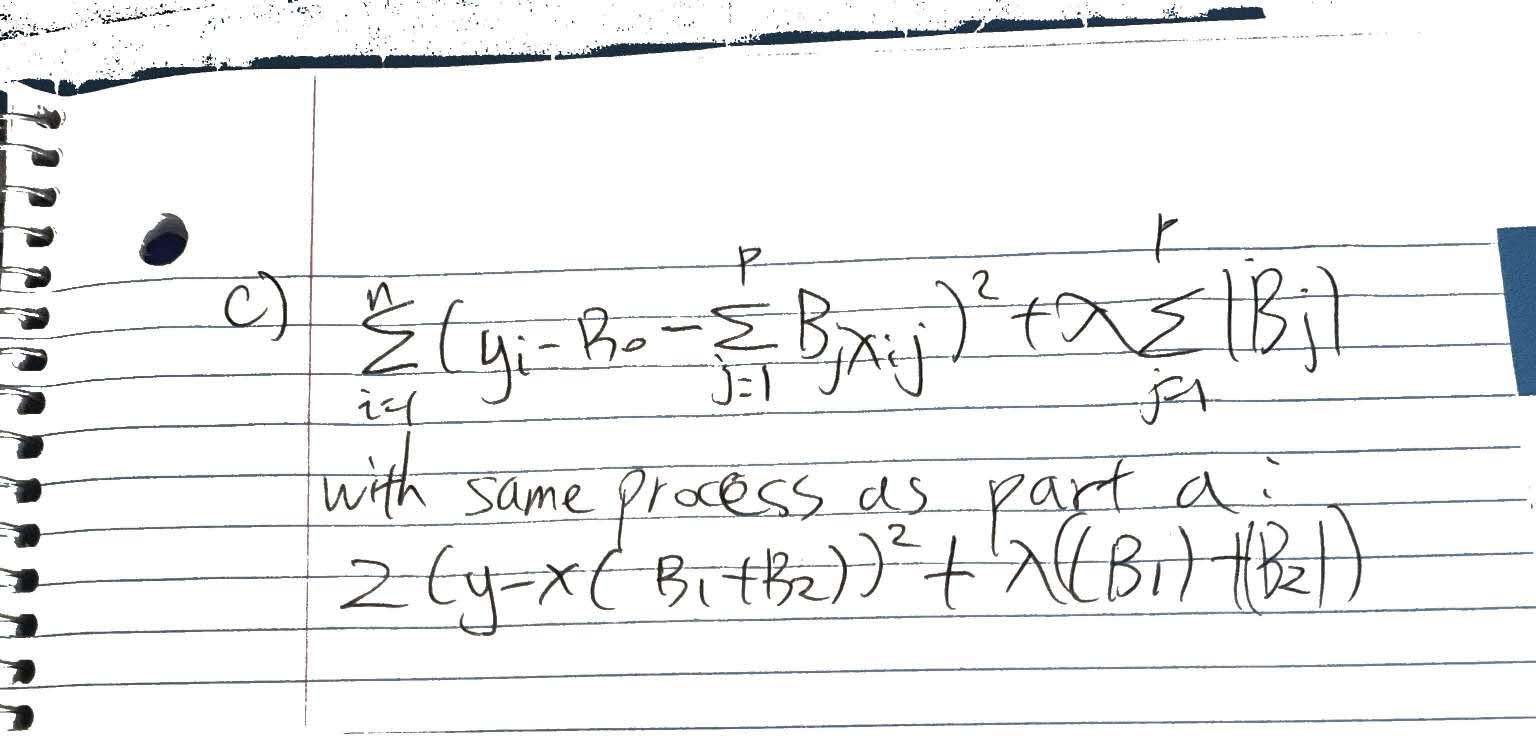

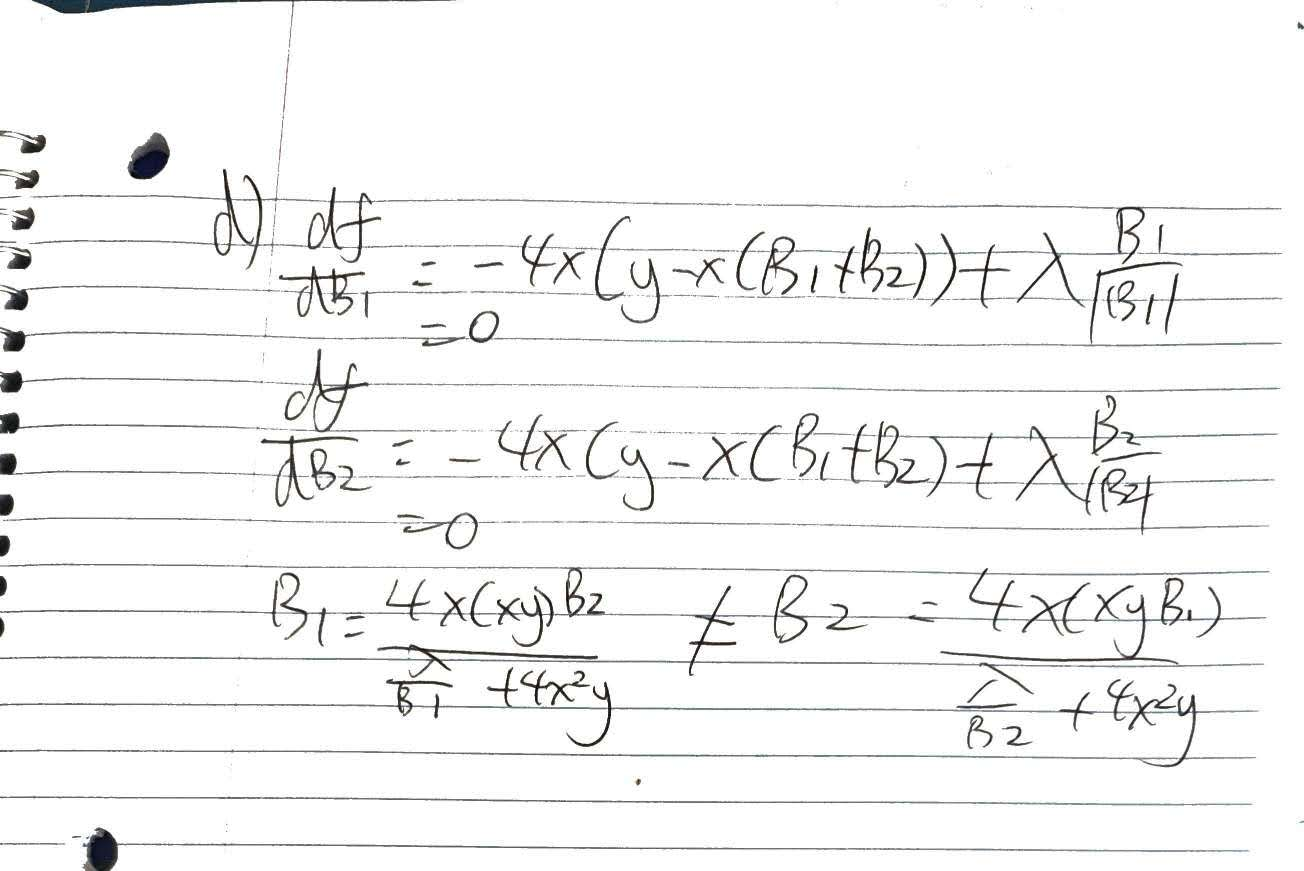

## 4. ISLR 8.4.5

Majority vote: Six values above 0.5 for red, four for green. The final classification is red.
Average probability: (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75)/10 = 0.45. The final classification is green.
 

## 5. ISLR 9.7.3

(a)

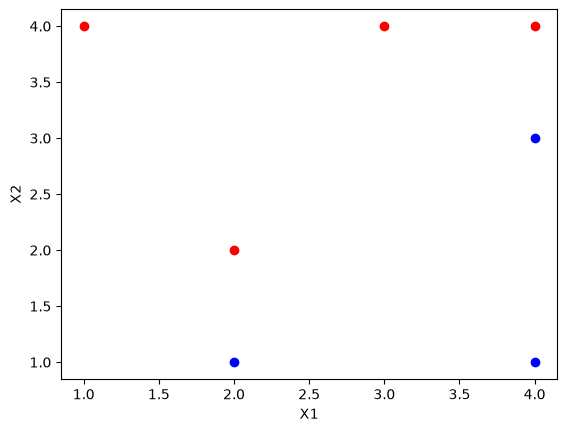

In [13]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

(b) x2 - x1 + 0.5 = 0

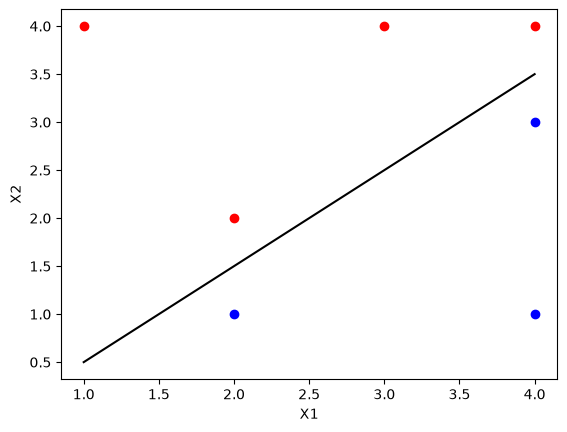

In [14]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue")
plt.plot([1, 4], [0.5, 3.5], color="black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

(c) x is classified as red if x2 - x1 + 0.5 > 0 and blue if x2 - x1 + 0.5 < 0 
B0 = 0.5, B1 = -1, B2 = 1

(d)

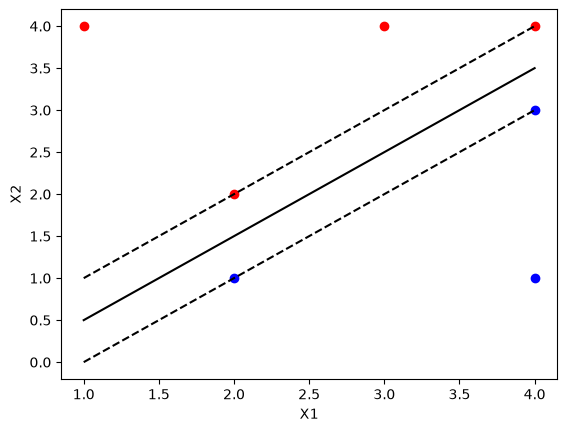

In [15]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue")
plt.plot([1, 4], [0.5, 3.5], color="black")
plt.plot([1, 4], [1, 4], "k--")
plt.plot([1, 4], [0, 3], "k--")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

(e) The support vectors are (2,2), (4,4), (2,1), (4,3)

(f) (4,1) is not a support vector and is far from the margin so slight movement would not affect the maximal margin hyperplane

(g) x2 - x1 + 0.1 = 0

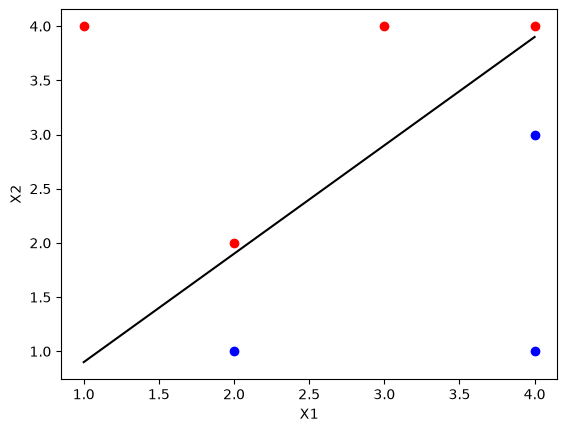

In [17]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue")
plt.plot([1, 4], [0.9, 3.9], color="black")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

(h) (3,3)

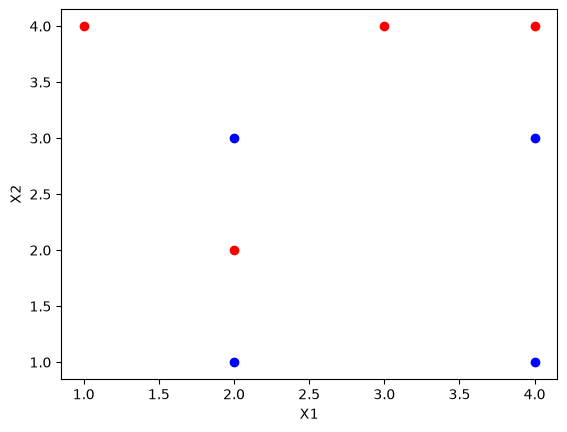

In [23]:
plt.scatter([3, 2, 4, 1], [4, 2, 4, 4], color="red")
plt.scatter([2, 4, 4], [1, 3, 1], color="blue")
plt.scatter(2, 3, color="blue")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()